# From a PD to capital: the IRB function, the large homogeneous portfolio and the TTC portfolio

**Question:** What does a bank hold against a book of S&P-rated corporates once its PDs go through the Basel IRB function; how much of that comes from the tail year the function insures against, from the PD floor and from the regime; and does projecting the book with a migration matrix keep its PD where the economy left it?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 05 of this topic (a PD by grade and the price of a calibration)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say what the large homogeneous portfolio (LHP) is, and read its distribution, its quantiles and the credit-cycle factor that an observed default rate implies;
- take one exposure through the Basel III IRB function, see the asset correlation, the 99.9% conditional PD, the maturity adjustment, K and the risk weight, and read how the risk weight moves with the PD;
- compare four regulatory regimes and say which of their differences are the PD floor and which are the 1.06 factor of Basel II;
- turn the long-run PDs of a rating agency into the average risk weight of a portfolio, and see where the PD floor binds;
- explain why a projection by a migration matrix drifts to a portfolio of its own, on Engelmann's printed paths and on the S&P matrix.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import ttc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files, from cases C04 and C01 (https://registers.esma.europa.eu/cerep-publication/ for the S&P cohorts, licence class `mirror-allowed`):

- `data/derived/C04/sp.json`: the S&P long-run PDs by grade under two definitions of default (`outputs.lra.d2`, `outputs.lra.d4`), the 26 cohorts with their sizes (the grade mix of the portfolio), the pooled matrix, the origination mix and the IRB assumptions of the case (`outputs.irb`).
- `data/derived/C04/published.json`: Engelmann's (2024) printed 50-year paths of four starting portfolios (`outputs.engelmann`).
- `data/derived/C01/holdout.json`: the grid of retail exposures of case C01 (`outputs.irb.parity`), used here only for the PDs, LGDs and regimes it lists.

The IRB assumptions of C04 are those of Basel III final for a corporate exposure: LGD 45% (the F-IRB value for senior unsecured claims on financial institutions, CRE32.6; other corporates have 40%), used with the non-financial corporate correlation and without the 1.25 multiplier of CRE31.7, which is the case's assumption; maturity 2.5 years (CRE32.44) and a PD floor of 0.05% (CRE32.4). The framework is at https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27.

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
sp = json.loads((DERIVED / "C04" / "sp.json").read_text(encoding="utf-8"))
published = json.loads((DERIVED / "C04" / "published.json").read_text(encoding="utf-8"))
holdout = json.loads((DERIVED / "C01" / "holdout.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades = out["grades"]

## Method

### Step 1: the large homogeneous portfolio

The one-factor model gives each obligor the asset return $A = \sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$ and a default when $A$ falls below $\Phi^{-1}(p)$. In a portfolio of many obligors with the same PD $p$ and correlation $\rho$, the idiosyncratic parts average out and the fraction of defaults converges to the conditional PD $p(Z)$ (Vasicek, 2002; Gordy, 2003): the **large homogeneous portfolio** (LHP). Its distribution function and its $q$-quantile are

$$P(L \le x) = \Phi\!\left(\frac{\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(p)}{\sqrt{\rho}}\right), \qquad L_q = \Phi\!\left(\frac{\Phi^{-1}(p) + \sqrt{\rho}\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

The IRB formula's conditional PD is this quantile at $q = 0.999$: the default rate of the portfolio in a one-in-a-thousand year. The engine has the functions in `engines.vasicek`. The next cell takes the through-the-cycle (TTC) PD of the S&P cohort mix, 0.61% from notebook 01, with the Basel III corporate asset correlation at that PD, and reads four quantiles of the portfolio default rate. It also reads the factor $Z$ that the latest cohort's default rate implies.

In [3]:
# Quantiles of the LHP default rate at the TTC PD, and the credit-cycle factor of the latest cohort
ttc_pd = sp["impact"]["ttc_default_rate"]["value"]
latest_rate = sp["impact"]["latest_default_rate"]["value"]
rho = irb.correlation("corporate", ttc_pd)
levels = np.array([0.5, 0.9, 0.99, 0.999])
quantiles = vasicek.lhp_quantile(levels, ttc_pd, rho)
z_latest = float(vasicek.implied_factor(latest_rate, ttc_pd, rho))

print(f"TTC PD {ttc_pd:.4f}, Basel III correlation {rho:.4f}")
print(f"latest cohort default rate {latest_rate:.4f}, implied factor {z_latest:.2f}")
print(f"share of years with a rate below the PD {float(vasicek.lhp_cdf(ttc_pd, ttc_pd, rho)):.3f}")
for q, x in zip(levels, quantiles):
    print(f"year at {q:.3f}: default rate {x:.4f} = {x / ttc_pd:.1f} times the PD")

TTC PD 0.0061, Basel III correlation 0.2085
latest cohort default rate 0.0077, implied factor -0.77
share of years with a rate below the PD 0.728
year at 0.500: default rate 0.0024 = 0.4 times the PD
year at 0.900: default rate 0.0154 = 2.5 times the PD
year at 0.990: default rate 0.0523 = 8.6 times the PD
year at 0.999: default rate 0.1091 = 17.9 times the PD


In a median year the portfolio defaults at well under the PD, because the distribution is skewed: most years are calm and a few are bad. The figure draws the distribution function on a logarithmic axis, so that the tail is visible, with the four quantiles marked and the TTC PD as a reference.

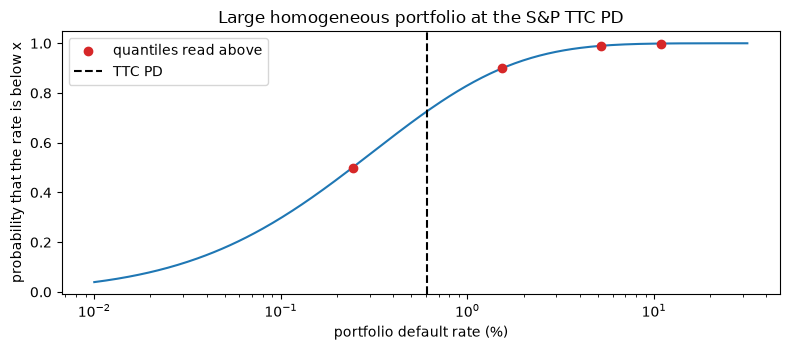

In [4]:
# Draw the distribution function of the portfolio default rate with its quantiles
rates = np.logspace(-4, -0.5, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(100 * rates, vasicek.lhp_cdf(rates, ttc_pd, rho), color="tab:blue")
ax.scatter(100 * quantiles, levels, color="tab:red", zorder=3, label="quantiles read above")
ax.axvline(100 * ttc_pd, color="black", linestyle="--", label="TTC PD")
ax.set_xscale("log")
ax.set_xlabel("portfolio default rate (%)")
ax.set_ylabel("probability that the rate is below x")
ax.set_title("Large homogeneous portfolio at the S&P TTC PD")
ax.legend()
fig.tight_layout()
plt.show()

The curve rises quickly through the low rates and then flattens into a long tail: a median year defaults at 0.4 times the PD, the portfolio rate stays below its own PD in 72% of the years, and the 99.9% year defaults at about eighteen times the PD. That tail, and not the average, is what bank capital covers. The red points do not show how likely the tail is in practice: they come from the model's single factor and a correlation taken from the regulation, so they say how large a bad year is if the model is right. The latest cohort sits at a factor slightly below zero, a little worse than the average cycle.

### Step 2: one exposure through the IRB function

The Basel III IRB capital requirement of a non-retail exposure (CRE31.5) is the loss in the 99.9% year less the expected loss, with a maturity adjustment:

$$K = \left[\mathrm{LGD}\,\Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) + \sqrt{R}\,\Phi^{-1}(0.999)}{\sqrt{1-R}}\right) - \mathrm{PD}\cdot\mathrm{LGD}\right]\frac{1 + (M - 2.5)\,b}{1 - 1.5\,b}, \quad b = (0.11852 - 0.05478 \ln \mathrm{PD})^2$$

The asset correlation is $R = 0.12\,\frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}} + 0.24\left(1 - \frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}}\right)$ (CRE31.5): it falls from 24% for a very safe obligor to 12% for a very risky one. The risk weight is $12.5\,K$, a share of the exposure. The term in brackets is the LHP quantile of Step 1 at $q = 0.999$ times the LGD. The engine's `capital_requirement` returns an `IRBResult` with every intermediate. The next cell takes a corporate exposure with PD 1%, LGD 45% and maturity 2.5 years, and rebuilds $K$ from the LHP quantile and the result's maturity adjustment, so that the two engine modules can be read side by side.

In [5]:
# One corporate exposure through the engine's IRB function, and K rebuilt from the LHP quantile
pd_one, lgd, maturity = 0.01, 0.45, 2.5
result = irb.capital_requirement("corporate", pd_one, lgd, maturity=maturity, regime="basel3")
conditional = float(vasicek.lhp_quantile(0.999, pd_one, result.correlation))
k_rebuilt = lgd * (conditional - pd_one) * result.maturity_adjustment

print(f"asset correlation {result.correlation:.4f}, PD in the 99.9% year {conditional:.4f}")
print(f"maturity adjustment {result.maturity_adjustment:.4f}")
print(f"K {result.k:.5f} (rebuilt from the LHP quantile {k_rebuilt:.5f})")
print(f"risk weight {result.risk_weight:.4f}")
print(f"capital per 100 of exposure at 8% {100 * result.risk_weight * 0.08:.3f}")

asset correlation 0.1928, PD in the 99.9% year 0.1403
maturity adjustment 1.2598
K 0.07385 (rebuilt from the LHP quantile 0.07385)
risk weight 0.9232
capital per 100 of exposure at 8% 7.385


The exposure carries a correlation of 0.19 and a conditional PD of 14% in the bad year, fourteen times its own PD. Once the expected loss is taken out and the maturity adjustment applied, K is 7.4% of the exposure and the risk weight 92%: the bank holds about seven and a half of capital per hundred lent. The rebuilt K equals the engine's, so the two modules agree on what the formula means. The next figure sweeps the PD to show how the weight and the correlation move.

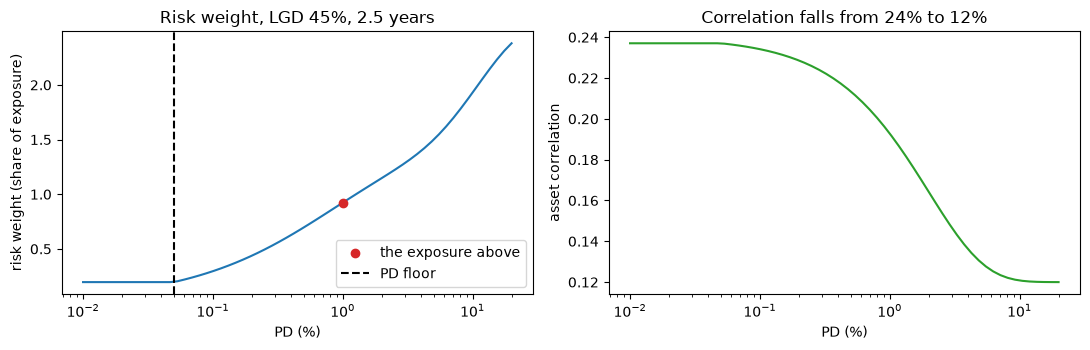

In [6]:
# Sweep the PD: risk weight and asset correlation of the corporate exposure under Basel III
pd_axis = np.logspace(-4, -0.7, 60)
sweep = [irb.capital_requirement("corporate", p, lgd, maturity=maturity, regime="basel3") for p in pd_axis]
floor = irb.REGIMES["basel3"].pd_floor

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(100 * pd_axis, [r.risk_weight for r in sweep], color="tab:blue")
left.scatter(100 * pd_one, result.risk_weight, color="tab:red", zorder=3, label="the exposure above")
left.axvline(100 * floor, color="black", linestyle="--", label="PD floor")
left.set_xscale("log")
left.set_xlabel("PD (%)")
left.set_ylabel("risk weight (share of exposure)")
left.set_title("Risk weight, LGD 45%, 2.5 years")
left.legend()
right.plot(100 * pd_axis, [r.correlation for r in sweep], color="tab:green")
right.set_xscale("log")
right.set_xlabel("PD (%)")
right.set_ylabel("asset correlation")
right.set_title("Correlation falls from 24% to 12%")
fig.tight_layout()
plt.show()

Below the dashed line the curve is flat: a PD under the floor is raised to the floor before the formula runs. Above it the weight rises with the PD but flattens, because the correlation on the right falls as the obligor gets riskier. A riskier obligor therefore adds capital less than proportionally to its PD. The red point is the 1% exposure of the previous cell. Nothing in the figure says that a higher weight is a worse bank decision: the function prices only the unexpected loss, and the expected loss is covered by provisions.

### Step 3: regimes, floors and the 1.06 factor

The engine holds four regimes (`irb.REGIMES`): Basel III final, the EU's CRR3 (Article 153), Basel II as in force until 2022, and the Chilean regulator's internal methods (RAN 21-6). They differ in two things that this notebook can see: the PD floor (0.05% in Basel III and CRR3, 0.03% in Basel II) and the 1.06 scaling factor on risk-weighted assets, which exists in Basel II (CRE30.4) and in neither Basel III final nor CRR3 Article 153. The next cell prices the same corporate exposure under the four regimes over a sweep of PDs, and prints the weights at three of them. It then prices the retail classes of case C01 under two of the regimes of its grid, using the grid's PDs at an LGD of 50%.

In [7]:
# The same corporate exposure under the four regimes over a PD sweep, and the retail classes of the C01 grid
weights = {}
for regime_id in irb.REGIMES:
    weights[regime_id] = np.array(
        [irb.capital_requirement("corporate", p, lgd, maturity=maturity, regime=regime_id).risk_weight for p in pd_axis]
    )
for at in (5, 25, 55):
    row = " ".join(f"{regime_id} {weights[regime_id][at]:.4f}" for regime_id in irb.REGIMES)
    ratio = weights["basel2"][at] / weights["basel3"][at]
    print(f"PD {pd_axis[at]:.4f}: {row} | basel2 / basel3 {ratio:.3f}")

retail_pds = sorted({point["pd"] for point in holdout["outputs"]["irb"]["parity"]})
retail = {}
for regime_id in ("basel3", "basel2"):
    for label, asset, revolver in (("QRRE revolver", "qrre", True), ("other retail", "other_retail", False)):
        retail[(regime_id, label)] = [
            irb.capital_requirement(asset, p, 0.5, revolver=revolver, regime=regime_id).risk_weight for p in retail_pds
        ]

PD 0.0002: basel3 0.1965 crr3 0.1965 basel2 0.1531 cl_ran21_6 0.1965 | basel2 / basel3 0.779
PD 0.0025: basel3 0.4949 crr3 0.4949 basel2 0.5246 cl_ran21_6 0.4949 | basel2 / basel3 1.060
PD 0.1192: basel3 2.0567 crr3 2.0567 basel2 2.1801 cl_ran21_6 2.0567 | basel2 / basel3 1.060


The left panel of the next figure is the ratio of the Basel II, CRR3 and RAN 21-6 weights to the Basel III weight along the PD sweep. The right panel draws the retail weights at the grid's PDs. The ratio shows the two effects separately: a dip where the two floors disagree, and a constant where they do not.

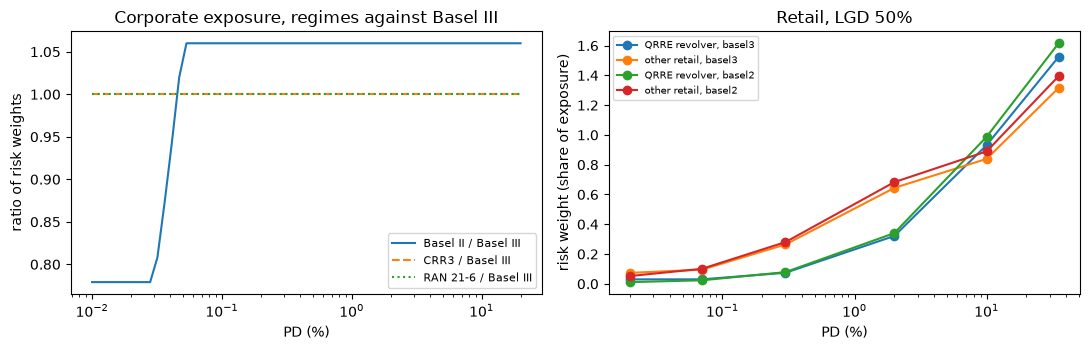

In [8]:
# Draw the regime ratios and the retail weights
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(100 * pd_axis, weights["basel2"] / weights["basel3"], label="Basel II / Basel III")
left.plot(100 * pd_axis, weights["crr3"] / weights["basel3"], label="CRR3 / Basel III", linestyle="--")
left.plot(100 * pd_axis, weights["cl_ran21_6"] / weights["basel3"], label="RAN 21-6 / Basel III", linestyle=":")
left.set_xscale("log")
left.set_xlabel("PD (%)")
left.set_ylabel("ratio of risk weights")
left.set_title("Corporate exposure, regimes against Basel III")
left.legend(fontsize=8)
for (regime_id, label), values in retail.items():
    right.plot(100 * np.array(retail_pds), values, marker="o", label=f"{label}, {regime_id}")
right.set_xscale("log")
right.set_xlabel("PD (%)")
right.set_ylabel("risk weight (share of exposure)")
right.set_title("Retail, LGD 50%")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

On the left, Basel II is exactly 1.06 times Basel III once the PD is above both floors. Below the Basel II floor of 0.03% the ratio is flat at about 0.78, because Basel II floors the PD lower and the Basel III weight stays at its own floor; between the two floors it climbs from one level to the other. CRR3 and the Chilean method trace the line at 1: for this corporate exposure they give the Basel III number. On the right, retail weights are set by the class and by the PD: at the lowest PDs other retail weighs more under Basel III, which has the higher floor, and from the middle of the range on the Basel II lines sit above the Basel III ones because of the scaling factor. The figure does not say that the regimes agree on other asset classes; it shows only the corporate and retail rows that the product prices.

### Step 4: from long-run PDs to a portfolio's risk weight

Notebook 01 gave each grade its long-run PD under two definitions of default: `d2`, CEREP's default page, and `d4`, its transition page. The portfolio is the grade mix of the 26 cohorts, and its average risk weight is the mix-weighted sum of the grade risk weights. The grades AAA, AA and A have long-run PDs below 0.05%, so the PD floor binds there and their weight is that of the floor. The next cell prices every grade under both definitions with the engine and reports the grades it floored and the two portfolio weights. The gap between the two weights is the subject of notebook 10.

In [9]:
# Risk weight of every grade under both definitions of default, and the average at the cohort mix
spec = out["irb"]
settings = {"lgd": spec["lgd"], "maturity": spec["maturity"], "regime": spec["regime"]}
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
by_grade, portfolio, floored = {}, {}, {}
for definition in ("d2", "d4"):
    rates_by_grade = out["lra"][definition]["rate"]
    results = [irb.capital_requirement(spec["asset_class"], float(p), **settings) for p in rates_by_grade]
    by_grade[definition] = np.array([r.risk_weight for r in results])
    floored[definition] = [grades[i] for i, r in enumerate(results) if r.pd_applied != r.pd_input]
    portfolio[definition] = float(mix @ by_grade[definition])
    print(f"{definition}: portfolio risk weight {portfolio[definition]:.4f}")
    print(f"{definition}: grades at the floor {floored[definition]}")
print(f"weight under d4 over weight under d2 {portfolio['d4'] / portfolio['d2']:.3f}")

d2: portfolio risk weight 0.5797
d2: grades at the floor ['AAA', 'AA', 'A']
d4: portfolio risk weight 0.4745
d4: grades at the floor ['AAA', 'AA', 'A']
weight under d4 over weight under d2 0.819


The figure shows the weight of each grade under the two definitions, with the portfolio averages as horizontal lines. The first three bars are equal because they sit on the floor.

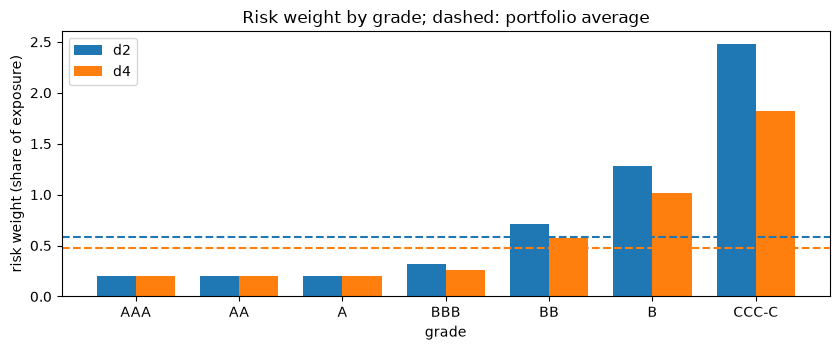

In [10]:
# Draw the risk weight by grade under the two definitions with the portfolio averages
fig, ax = plt.subplots(figsize=(8.5, 3.6))
width = 0.38
for k, definition in enumerate(("d2", "d4")):
    bars = ax.bar(np.arange(7) + (k - 0.5) * width, by_grade[definition], width, label=definition)
    ax.axhline(portfolio[definition], color=bars[0].get_facecolor(), linestyle="--")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_xlabel("grade")
ax.set_ylabel("risk weight (share of exposure)")
ax.set_title("Risk weight by grade; dashed: portfolio average")
ax.legend()
fig.tight_layout()
plt.show()

AAA, AA and A weigh the same under both definitions, 0.1965, because their long-run PDs are under the floor; the difference between the definitions comes entirely from BBB downwards, and above all from CCC-C, where the long-run PD is 26.6% under `d2` and 8.6% under `d4`. The dashed lines are the portfolio averages, which also depend on the mix: BBB, BB and A hold most of the exposure, so the large weight of CCC-C counts for little in the average. The figure shows what the definition does to capital and not which definition is right.

### Step 5: a projection that drifts to a portfolio of its own

A stress-testing model often projects a portfolio year after year with a migration matrix $T$, writes off the defaulted part and re-originates it with a vector $O$ to keep the balance constant (Engelmann, 2024):

$$W_t' = W_{t-1}'\,T\,I_w + \bigl(W_{t-1}'\,T\,V_w\bigr)\,O'$$

with $I_w$ the identity whose last diagonal entry is 0 and $V_w$ the default column. Engelmann shows that, if the performing block of $T$ is primitive and nothing is originated in default, the iteration converges to a unique through-the-cycle portfolio $W_{\mathrm{ttc}}$ whatever the starting portfolio. The convergence is not monotone: the portfolio PD can rise and fall on its way, a spurious recession or boom produced by the matrix and not by the economy. The engine's `ttc.project` applies this map. The next cell starts from the latest cohort's grade mix, re-originates with the observed origination mix, and projects 15 years under the pooled S&P matrix. It also reads the four printed paths of Engelmann (the paper's matrix, 50 years) and prints their start, their extreme and their end.

In [11]:
# Project the latest cohort's mix under the pooled S&P matrix, and read Engelmann's four printed paths
pooled = np.array(out["pooled"]["matrix"], dtype=float)
origination = np.array(out["origination"], dtype=float)
latest = np.array(out["cohorts"][-1]["size"], dtype=float)
latest_mix = np.append(latest / latest.sum(), 0.0)
projection = ttc.project(pooled, latest_mix, origination, years=15)
sp_rates = projection["default_rate"]
sp_ttc = projection["ttc"]["default_rate"]
print(f"S&P: year 1 {sp_rates[0]:.4f}, year 15 {sp_rates[-1]:.4f}, TTC {sp_ttc:.4f}")
print(f"S&P: peak {sp_rates.max():.4f} in year {sp_rates.argmax() + 1}")

engelmann = published["outputs"]["engelmann"]
for pf in engelmann["portfolios"]:
    path = np.array(pf["pd_path"])
    high, low = f"{path.max():.5f} ({path.argmax()})", f"{path.min():.5f} ({path.argmin()})"
    print(f"{pf['name']:9s} start {path[0]:.5f}, highest {high}, lowest {low}, end {path[-1]:.5f}")
print(f"TTC PD of the paper: {engelmann['ttc_pd']['printed']}")

S&P: year 1 0.0077, year 15 0.0074, TTC 0.0061
S&P: peak 0.0080 in year 4
W_init    start 0.01161, highest 0.01697 (6), lowest 0.01161 (0), end 0.01236
W_init 2  start 0.02724, highest 0.02724 (0), lowest 0.00722 (20), end 0.01010
W tilde   start 0.01827, highest 0.02140 (4), lowest 0.01237 (49), end 0.01237
W hat     start 0.01095, highest 0.01195 (49), lowest 0.01095 (0), end 0.01195
TTC PD of the paper: 0.01198


The figure draws the four printed paths against the TTC PD on the left, and the projection of the S&P portfolio against its TTC default rate on the right.

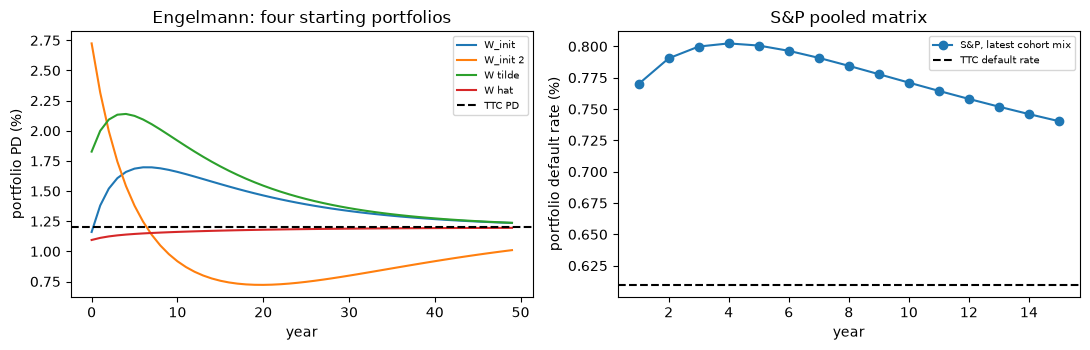

In [12]:
# Draw Engelmann's four printed paths and the S&P projection against their TTC levels
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for pf in engelmann["portfolios"]:
    left.plot(100 * np.array(pf["pd_path"]), label=pf["name"])
left.axhline(100 * engelmann["ttc_pd"]["printed"], color="black", linestyle="--", label="TTC PD")
left.set_xlabel("year")
left.set_ylabel("portfolio PD (%)")
left.set_title("Engelmann: four starting portfolios")
left.legend(fontsize=7)
right.plot(range(1, 16), 100 * sp_rates, marker="o", label="S&P, latest cohort mix")
right.axhline(100 * sp_ttc, color="black", linestyle="--", label="TTC default rate")
right.set_xlabel("year")
right.set_ylabel("portfolio default rate (%)")
right.set_title("S&P pooled matrix")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

On the left, three of the four starting portfolios take a detour. One starts near 1.2%, climbs to 1.7% within six years and then settles near the TTC PD; another starts at 2.7%, undershoots to 0.7% around year 20 and rises back. Only the fourth moves in one direction. Each hump would read as a recession or a boom in a stress test, yet the economy is not in the model: the matrix alone makes it. On the right, the S&P portfolio starts above its TTC rate, rises a little more and then declines slowly, still above the TTC rate after 15 years. The figure does not say that stress tests are wrong, only that a horizon shorter than the convergence confuses the starting mix with the scenario.

## Results

**Answer:** At the S&P TTC PD of 0.0061 the large homogeneous portfolio defaults at 0.1091 in a 99.9% year, 17.9 times its PD, and a corporate exposure with PD 1%, LGD 45% and maturity 2.5 years carries K of 0.07385 and a risk weight of 0.9232: 7.385 of capital per 100 lent. The PD floor makes the AAA, AA and A weights equal, 0.1965, the regime moves the weight by the 1.06 factor of Basel II above the floors, and the definition of default moves the portfolio's average weight from 0.5797 under `d2` to 0.4745 under `d4`, a ratio of 0.819. A projection by the pooled S&P matrix does not hold the PD where the economy left it: the default rate goes from 0.0077 to a peak of 0.0080 in year 4 and is still 0.0074 in year 15, against a TTC rate of 0.0061.

- **The tail, not the average.** The LHP default rate at the TTC PD is 0.0024 in the median year, 0.0154 in a 90% year, 0.0523 in a 99% year and 0.1091 in a 99.9% year; the portfolio stays below its own PD in 72% of the years. The correlation at that PD is 0.2085 and the latest cohort's rate of 0.0077 implies a factor of -0.77.
- **One exposure.** The correlation is 0.1928, the PD in the 99.9% year 0.1403, the maturity adjustment 1.2598 and K 0.07385, equal to K rebuilt from the LHP quantile. Past the floor the weight rises with the PD and flattens as the correlation falls from about 24% to 12%.
- **Regimes.** At PDs of 0.0002, 0.0025 and 0.1192 Basel III and CRR3 weigh 0.1965, 0.4949 and 2.0567 and RAN 21-6 gives the same numbers; Basel II weighs 0.1531, 0.5246 and 2.1801, a ratio to Basel III of 0.779 under its own floor and of 1.060 above both floors.
- **From PDs to a portfolio.** The floor binds for AAA, AA and A under both definitions. The cohort mix has an average weight of 0.5797 with the default-page PDs and 0.4745 with the transition-page PDs, 0.819 times the first, the subject of notebook 10.
- **The drift.** Engelmann's printed paths: W_init starts at 0.01161, rises to 0.01697 in year 6 and ends at 0.01236; W_init 2 starts at 0.02724, falls to 0.00722 in year 20 and ends at 0.01010; W tilde starts at 0.01827, rises to 0.02140 in year 4 and ends at 0.01237; only W hat is monotone. The paper's TTC PD is 0.01198.

What this notebook does not show: the Basel III output floor and the standardised approach (outside this product's IRB cases), or how the choice of PD moves capital across calibration approaches (notebook 09).

## Summary

- The IRB risk weight is the loss in a 99.9% year of a large homogeneous portfolio less the expected loss, with a maturity adjustment; the engine's IRB and Vasicek modules agree on it.
- The weight rises with the PD but flattens, because the asset correlation falls from 24% to 12%; below the floor it is flat.
- Regimes differ by the PD floor and by the 1.06 factor of Basel II; Basel III final and CRR3 give the same weight on a corporate exposure.
- A long-run PD below the floor weighs as the floor, and the definition of default moves a portfolio's weight by about a fifth.
- A projection by a migration matrix drifts to a portfolio of its own and its PD can rise and fall on the way: a spurious cycle.

**What to try next.** Change the LGD of Step 2 to 0.40 and the maturity to 1 and 5 years and read how K moves; then read notebook 08.

## References

- BCBS, Basel Framework, CRE31 (IRB approach: risk-weight functions) and CRE32 (risk components: LGD, maturity, PD floor), and CRE30.4 for the Basel II scaling factor. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), doi 10.1016/S1042-9573(03)00040-8.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, equations 9 and 10, Theorem 1 and section 4.
- Regulation (EU) 2024/1623 (CRR3), Article 153, for the EU regime.